# 新潟ポジショニング分析 Phase 1
## SSDSE-B-2026 による都道府県クラスタリング & 外れ値探索

**データ:** 独立行政法人統計センター「SSDSE-県別推移 2025年版」  
**分析フロー:**
```
CSV読込 → 特徴量エンジニアリング → 標準化
→ UMAP(次元圧縮) → HDBSCAN(クラスタリング) → LOF(外れ値スコア)
→ Plotly インタラクティブ可視化 → 戦略仮説生成
```

**必要なファイル:** `SSDSE-B-2026.csv`（このノートブックと同じフォルダに置く）

---
## 0. セットアップ

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import umap
import hdbscan
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor

# ---- CSVファイルのパス（必要に応じて変更） ----
CSV_PATH = "SSDSE-B-2026.csv"
TARGET_YEAR = 2022   # 最新年

print("セットアップ完了")

セットアップ完了


---
## 1. データ読み込み & 前処理

SSDSEのCSVは **1行目=コード名、2行目=日本語列名、3行目以降=データ** という2重ヘッダー構造です。  
`skiprows=1` で日本語ヘッダーを使って読み込みます。

In [2]:
# 読み込み（shift-jis, 日本語ヘッダー行を使用）
df_raw = pd.read_csv(CSV_PATH, encoding='shift-jis', skiprows=1)

print(f"全データ shape: {df_raw.shape}")
print(f"年度: {sorted(df_raw['年度'].unique())}")
print(f"都道府県数: {df_raw['都道府県'].nunique()}")
print(f"欠損値: {df_raw.isnull().sum().sum()} 件")

# 最新年（2022年）に絞る
df = df_raw[df_raw['年度'] == TARGET_YEAR].copy().reset_index(drop=True)
print(f"\n{TARGET_YEAR}年 shape: {df.shape}")
df[['都道府県','総人口','合計特殊出生率','転出者数（日本人移動者）']].head()

全データ shape: (564, 112)
年度: [np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
都道府県数: 47
欠損値: 0 件

2022年 shape: (47, 112)


,都道府県,総人口,合計特殊出生率,転出者数（日本人移動者）
0,北海道,5140000,1.12,53107
1,青森県,1204000,1.24,20624
2,岩手県,1181000,1.21,19933
3,宮城県,2280000,1.09,43566
4,秋田県,930000,1.18,13306


---
## 2. 特徴量エンジニアリング

都道府県間で**規模の影響を除いた構造指標**を作ります。  
（人口の多い県が単純に目立つのを防ぐため、比率・密度に変換）

| グループ | 指標 | 意図 |
|---|---|---|
| 人口構造 | 年少・生産年齢・高齢化率 | 人口ピラミッドの形 |
| 人口動態 | 流出率・出生率・自然増減率 | 縮小の速度と質 |
| 労働市場 | 求人倍率・就職充足率 | 雇用の需給バランス |
| 教育 | 大学生比率・高校進学率 | 知識労働者の厚み |
| 観光 | 宿泊者数（人口比）・外国人比率 | 交流人口の質 |
| 生活 | 消費支出・住宅着工 | 経済活力・生活水準 |
| 子育て | 保育所待機児童率 | 少子化対策の実態 |

In [3]:
pop = df['総人口']  # 人口（分母に使う）

feat = pd.DataFrame({'都道府県': df['都道府県']})

# --- 人口構造 ---
feat['年少人口率']     = df['15歳未満人口']   / pop
feat['生産年齢人口率'] = df['15〜64歳人口']   / pop
feat['高齢化率']       = df['65歳以上人口']   / pop

# --- 人口動態 ---
feat['出生率']         = df['合計特殊出生率']
feat['転入率']         = df['転入者数（日本人移動者）'] / pop
feat['転出率']         = df['転出者数（日本人移動者）'] / pop
feat['社会増減率']     = (df['転入者数（日本人移動者）'] - df['転出者数（日本人移動者）']) / pop
feat['自然増減率']     = (df['出生数'] - df['死亡数']) / pop

# --- 労働市場 ---
# 求人倍率 = 月間有効求人数 / 月間有効求職者数
feat['求人倍率']       = df['月間有効求人数（一般）'] / df['月間有効求職者数（一般）'].replace(0, np.nan)
# 就職充足率 = 就職件数 / 月間有効求職者数
feat['就職充足率']     = df['就職件数（一般）'] / df['月間有効求職者数（一般）'].replace(0, np.nan)

# --- 教育 ---
feat['大学生比率']     = df['大学学生数'] / pop
feat['高校進学率']     = df['高等学校卒業者のうち進学者数'] / df['高等学校卒業者数'].replace(0, np.nan)
feat['中学進学率']     = df['中学校卒業者のうち進学者数'] / df['中学校卒業者数'].replace(0, np.nan)

# --- 観光・交流 ---
feat['宿泊者数_人口比']  = df['延べ宿泊者数'] / pop
feat['外国人宿泊比率']   = df['外国人延べ宿泊者数'] / df['延べ宿泊者数'].replace(0, np.nan)
feat['旅券発行率']       = df['一般旅券発行件数'] / pop

# --- 生活・経済 ---
feat['消費支出']         = df['消費支出（二人以上の世帯）']
feat['住宅着工_人口比']  = df['着工新設住宅戸数'] / pop
feat['ごみ1人排出量']    = df['1人1日当たりの排出量']
feat['リサイクル率']     = df['ごみのリサイクル率']

# --- 子育て ---
feat['保育所待機率']     = df['保育所等利用待機児童数'] / df['保育所等定員数'].replace(0, np.nan)
feat['保育所充足率']     = df['保育所等在所児数'] / df['保育所等定員数'].replace(0, np.nan)

# --- 医療 ---
feat['病院数_人口比']    = df['一般病院数'] / pop * 100000  # 10万人あたり
feat['診療所数_人口比']  = df['一般診療所数'] / pop * 100000

FEATURE_COLS = [c for c in feat.columns if c != '都道府県']
print(f"特徴量数: {len(FEATURE_COLS)}")
print(f"欠損: {feat[FEATURE_COLS].isnull().sum().sum()} 件")
feat[['都道府県'] + FEATURE_COLS[:6]].head()

特徴量数: 24
欠損: 0 件


,都道府県,年少人口率,生産年齢人口率,高齢化率,出生率,転入率,転出率
0,北海道,0.103113,0.568872,0.328016,1.12,0.009549,0.010332
1,青森県,0.102159,0.550664,0.348007,1.24,0.013494,0.017130
2,岩手県,0.105843,0.548688,0.345470,1.21,0.013171,0.016878
3,宮城県,0.113158,0.597807,0.289035,1.09,0.019530,0.019108
4,秋田県,0.092473,0.520430,0.386022,1.18,0.011127,0.014308


In [4]:
# 標準化（欠損は中央値補完）
from sklearn.impute import SimpleImputer

X_raw = feat[FEATURE_COLS].values
X_imp = SimpleImputer(strategy='median').fit_transform(X_raw)
X_scaled = StandardScaler().fit_transform(X_imp)

# インデックス: 都道府県名
pref_names = feat['都道府県'].values
niigata_idx = list(pref_names).index('新潟県')
print(f"新潟県のインデックス: {niigata_idx}")
print(f"特徴量行列: {X_scaled.shape}")

新潟県のインデックス: 14
特徴量行列: (47, 24)


---
## 3. UMAP + HDBSCAN クラスタリング

In [5]:
# UMAP: 高次元→2D
# n_neighbors: 47都道府県なので8前後が適切。小さいほど局所構造重視
# min_dist: 点の分散具合。小さいほど密集
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=8,
    min_dist=0.15,
    metric='euclidean',
    random_state=42
)
embedding = reducer.fit_transform(X_scaled)
print(f"UMAP embedding: {embedding.shape}")

UMAP embedding: (47, 2)


In [6]:
# HDBSCAN クラスタリング
# -1 = ノイズ（どのクラスターにも属さない外れ値）
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=4,
    min_samples=2,
    cluster_selection_method='eom'
)
cluster_labels = clusterer.fit_predict(embedding)

print("クラスター分布 (-1=ノイズ):")
for k, cnt in sorted(pd.Series(cluster_labels).value_counts().items()):
    prefs = [pref_names[i] for i, l in enumerate(cluster_labels) if l == k]
    print(f"  クラスター {k:2d} ({cnt}県): {', '.join(prefs)}")

クラスター分布 (-1=ノイズ):
  クラスター -1 (6県): 新潟県, 石川県, 兵庫県, 岡山県, 香川県, 沖縄県
  クラスター  0 (10県): 青森県, 岩手県, 秋田県, 山形県, 福島県, 福井県, 和歌山県, 徳島県, 愛媛県, 高知県
  クラスター  1 (10県): 富山県, 鳥取県, 島根県, 山口県, 佐賀県, 長崎県, 熊本県, 大分県, 宮崎県, 鹿児島県
  クラスター  2 (13県): 北海道, 宮城県, 茨城県, 栃木県, 群馬県, 山梨県, 長野県, 岐阜県, 静岡県, 愛知県, 三重県, 奈良県, 広島県
  クラスター  3 (4県): 埼玉県, 千葉県, 東京都, 神奈川県
  クラスター  4 (4県): 滋賀県, 京都府, 大阪府, 福岡県


---
## 4. LOF 外れ値スコア

In [7]:
# LOF: 局所密度に基づく外れ値スコア（大きいほど周囲と異質）
lof = LocalOutlierFactor(n_neighbors=5, contamination=0.15)
lof_pred   = lof.fit_predict(X_scaled)
lof_scores = -lof.negative_outlier_factor_  # 正値化（大=外れ値）

# 結果をDataFrameにまとめる
result = pd.DataFrame({
    '都道府県':   pref_names,
    'cluster':   cluster_labels,
    'lof_score': lof_scores,
    'is_outlier': lof_pred == -1,
    'umap_x':    embedding[:, 0],
    'umap_y':    embedding[:, 1],
})
result = result.merge(feat, on='都道府県')

# LOFランキング
print("LOFスコア Top 15（外れ値候補）:")
top = result.nlargest(15, 'lof_score')[['都道府県','lof_score','cluster','is_outlier']]
print(top.to_string(index=False))

LOFスコア Top 15（外れ値候補）:
都道府県  lof_score  cluster  is_outlier
 沖縄県   2.385801       -1        True
 東京都   1.564246        3        True
 京都府   1.560220        4        True
 北海道   1.346587        2        True
 愛知県   1.333264        2        True
 大阪府   1.288962        4        True
 高知県   1.279031        0        True
 福岡県   1.228737        4       False
 奈良県   1.145142        2       False
 埼玉県   1.139819        3       False
 宮城県   1.126981        2       False
 石川県   1.116790       -1       False
 長野県   1.107794        2       False
 山梨県   1.103155        2       False
 徳島県   1.097320        0       False


---
## 5. 可視化

### 5-1. UMAPマップ（メインビュー）

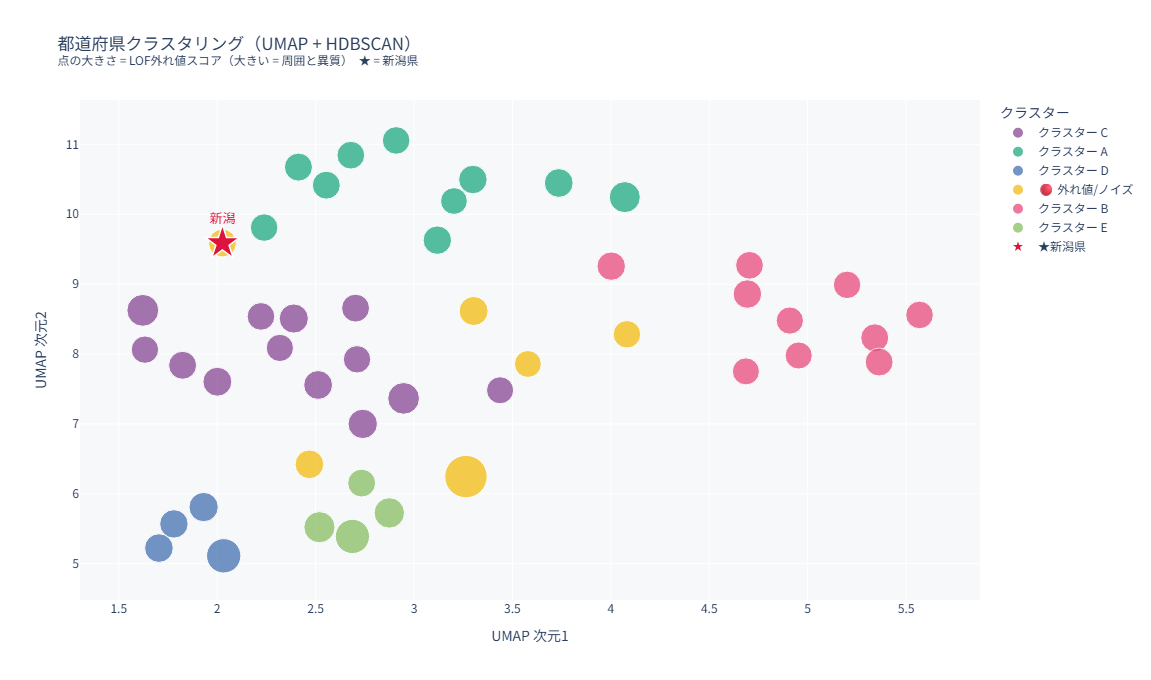

In [8]:
# クラスターに意味のある名前をつける（後で確認して手動更新してください）
CLUSTER_NAMES = {
    -1: '🔴 外れ値/ノイズ',
     0: 'クラスター A',
     1: 'クラスター B',
     2: 'クラスター C',
     3: 'クラスター D',
     4: 'クラスター E',
}
result['cluster_name'] = result['cluster'].map(
    lambda x: CLUSTER_NAMES.get(x, f'クラスター {x}')
)

# ホバーテキスト生成
def make_hover(row):
    return (
        f"<b>{row['都道府県']}</b><br>"
        f"クラスター: {row['cluster_name']}<br>"
        f"LOFスコア: {row['lof_score']:.2f}<br>"
        f"───────────────<br>"
        f"高齢化率:     {row['高齢化率']*100:.1f}%<br>"
        f"社会増減率:   {row['社会増減率']*100:.3f}%<br>"
        f"出生率:       {row['出生率']:.2f}<br>"
        f"求人倍率:     {row['求人倍率']:.2f}<br>"
        f"大学生比率:   {row['大学生比率']*100:.2f}%<br>"
        f"宿泊者数/人口: {row['宿泊者数_人口比']:.2f}<br>"
        f"消費支出:     {row['消費支出']:,.0f}円"
    )
result['hover'] = result.apply(make_hover, axis=1)

fig = px.scatter(
    result,
    x='umap_x', y='umap_y',
    color='cluster_name',
    size='lof_score',
    size_max=30,
    custom_data=['hover'],
    title='都道府県クラスタリング（UMAP + HDBSCAN）<br>'
          '<sup>点の大きさ = LOF外れ値スコア（大きい = 周囲と異質）　★ = 新潟県</sup>',
    color_discrete_sequence=px.colors.qualitative.Bold,
    width=950, height=680
)
fig.update_traces(hovertemplate='%{customdata[0]}<extra></extra>')

# 新潟を★でオーバーレイ
nrow = result.iloc[niigata_idx]
fig.add_trace(go.Scatter(
    x=[nrow['umap_x']], y=[nrow['umap_y']],
    mode='markers+text',
    marker=dict(symbol='star', size=26, color='crimson',
                line=dict(color='white', width=1.5)),
    text=['新潟'], textposition='top center',
    textfont=dict(size=13, color='crimson', family='sans-serif'),
    name='★新潟県', hoverinfo='skip'
))

fig.update_layout(
    xaxis_title='UMAP 次元1', yaxis_title='UMAP 次元2',
    legend_title='クラスター',
    plot_bgcolor='#f7f8fa',
    font=dict(family='sans-serif')
)
fig.show()

### 5-2. LOFスコア ランキングバー

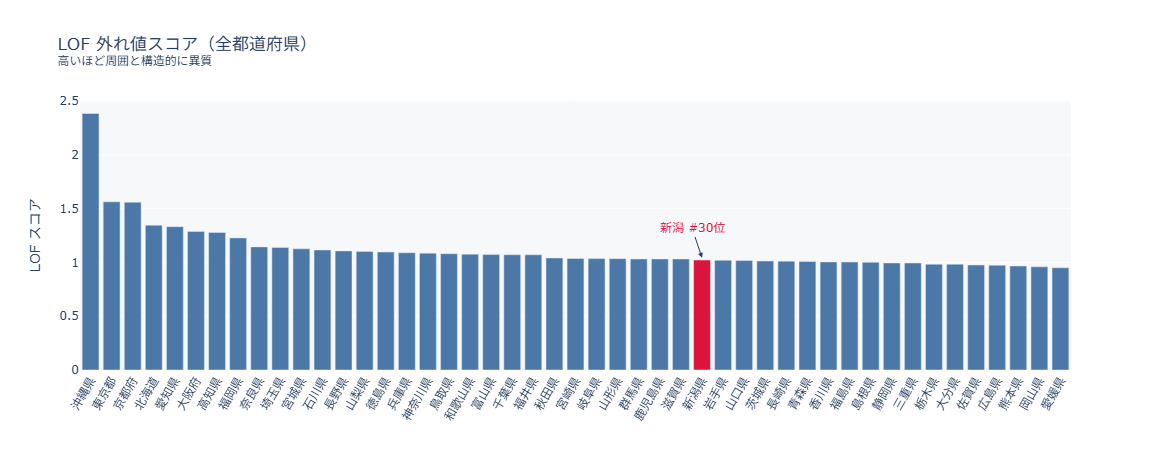

In [9]:
df_ranked = result.sort_values('lof_score', ascending=False).reset_index(drop=True)
df_ranked['rank'] = df_ranked.index + 1

# 新潟の順位
nii_rank = df_ranked[df_ranked['都道府県'] == '新潟県']['rank'].values[0]
nii_score = df_ranked[df_ranked['都道府県'] == '新潟県']['lof_score'].values[0]

colors = ['crimson' if p == '新潟県' else '#4C78A8' for p in df_ranked['都道府県']]

fig_lof = go.Figure(go.Bar(
    x=df_ranked['都道府県'],
    y=df_ranked['lof_score'],
    marker_color=colors,
    hovertemplate='%{x}: %{y:.3f}<extra></extra>'
))
fig_lof.add_annotation(
    x='新潟県', y=nii_score + 0.02,
    text=f'新潟 #{nii_rank}位',
    showarrow=True, arrowhead=2,
    font=dict(color='crimson', size=12)
)
fig_lof.update_layout(
    title='LOF 外れ値スコア（全都道府県）<br><sup>高いほど周囲と構造的に異質</sup>',
    xaxis_tickangle=-60, yaxis_title='LOF スコア',
    width=1000, height=450,
    plot_bgcolor='#f7f8fa'
)
fig_lof.show()

### 5-3. 新潟の Zスコアプロファイル（全国比）

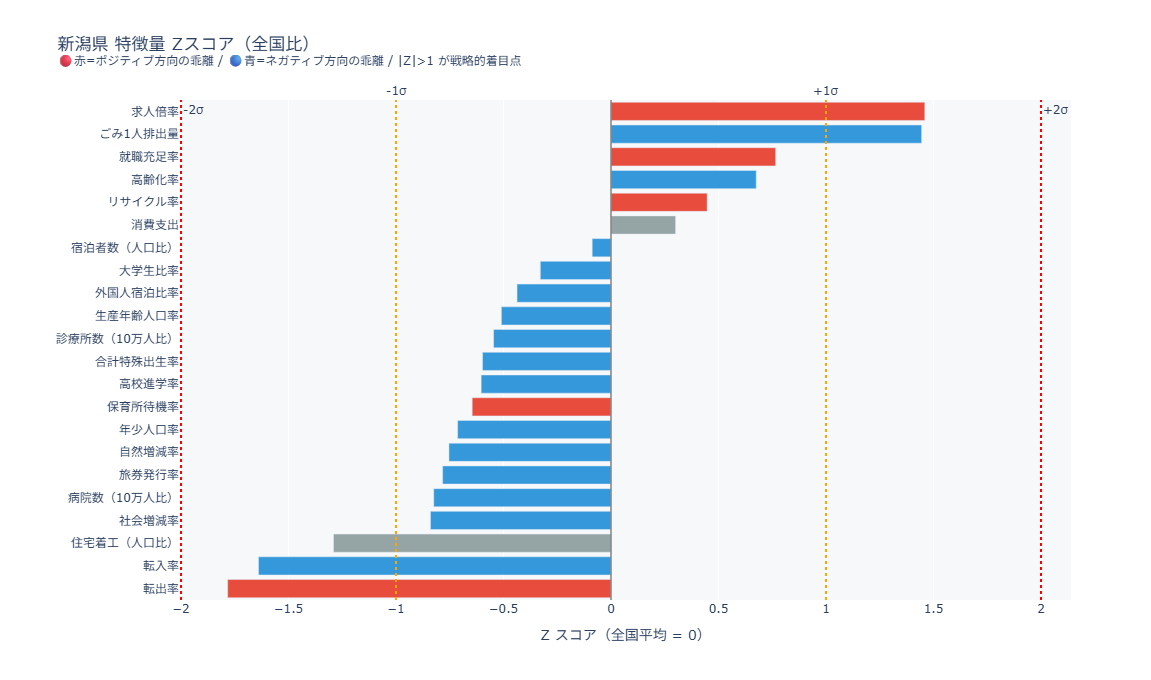

In [10]:
# 新潟の各指標のZスコアを棒グラフ化
FEAT_JP = {
    '年少人口率':      '年少人口率',
    '生産年齢人口率':  '生産年齢人口率',
    '高齢化率':        '高齢化率',
    '出生率':          '合計特殊出生率',
    '転入率':          '転入率',
    '転出率':          '転出率',
    '社会増減率':      '社会増減率',
    '自然増減率':      '自然増減率',
    '求人倍率':        '求人倍率',
    '就職充足率':      '就職充足率',
    '大学生比率':      '大学生比率',
    '高校進学率':      '高校進学率',
    '宿泊者数_人口比': '宿泊者数（人口比）',
    '外国人宿泊比率':  '外国人宿泊比率',
    '旅券発行率':      '旅券発行率',
    '消費支出':        '消費支出',
    '住宅着工_人口比': '住宅着工（人口比）',
    'ごみ1人排出量':   'ごみ1人排出量',
    'リサイクル率':    'リサイクル率',
    '保育所待機率':    '保育所待機率',
    '病院数_人口比':   '病院数（10万人比）',
    '診療所数_人口比': '診療所数（10万人比）',
}

z_niigata = pd.Series(
    X_scaled[niigata_idx],
    index=FEATURE_COLS
)

z_df = pd.DataFrame({
    'feature':    list(FEAT_JP.keys()),
    'feature_jp': list(FEAT_JP.values()),
    'z_score':    [z_niigata[f] for f in FEAT_JP.keys()],
})
z_df['abs_z'] = z_df['z_score'].abs()
z_df = z_df.sort_values('z_score')

# 高いほど良い指標 / 低いほど良い指標
HIGH_IS_GOOD = {'年少人口率','生産年齢人口率','出生率','転入率','社会増減率',
                '自然増減率','求人倍率','就職充足率','大学生比率','高校進学率',
                '宿泊者数_人口比','外国人宿泊比率','旅券発行率','リサイクル率',
                '保育所充足率','病院数_人口比','診療所数_人口比'}
LOW_IS_GOOD  = {'高齢化率','転出率','ごみ1人排出量','保育所待機率'}

def color_bar(row):
    z = row['z_score']
    feat = row['feature']
    if feat in HIGH_IS_GOOD:
        return '#e74c3c' if z > 0 else '#3498db'
    elif feat in LOW_IS_GOOD:
        return '#3498db' if z > 0 else '#e74c3c'  # 逆
    return '#95a5a6'

z_df['color'] = z_df.apply(color_bar, axis=1)

fig_z = go.Figure(go.Bar(
    x=z_df['z_score'],
    y=z_df['feature_jp'],
    orientation='h',
    marker_color=z_df['color'],
    hovertemplate='%{y}: Z=%{x:.2f}<extra></extra>'
))
fig_z.add_vline(x=0,   line_dash='solid', line_color='gray', line_width=1.5)
fig_z.add_vline(x=1,   line_dash='dot',   line_color='orange', annotation_text='+1σ', annotation_position='top')
fig_z.add_vline(x=-1,  line_dash='dot',   line_color='orange', annotation_text='-1σ', annotation_position='top')
fig_z.add_vline(x=2,   line_dash='dot',   line_color='red', annotation_text='+2σ')
fig_z.add_vline(x=-2,  line_dash='dot',   line_color='red', annotation_text='-2σ')
fig_z.update_layout(
    title='新潟県 特徴量 Zスコア（全国比）<br>'
          '<sup>🔴赤=ポジティブ方向の乖離 / 🔵青=ネガティブ方向の乖離 / |Z|>1 が戦略的着目点</sup>',
    xaxis_title='Z スコア（全国平均 = 0）',
    width=820, height=680,
    plot_bgcolor='#f7f8fa',
    margin=dict(l=180)
)
fig_z.show()

### 5-4. レーダーチャート：新潟 vs 同クラスター vs 全国平均

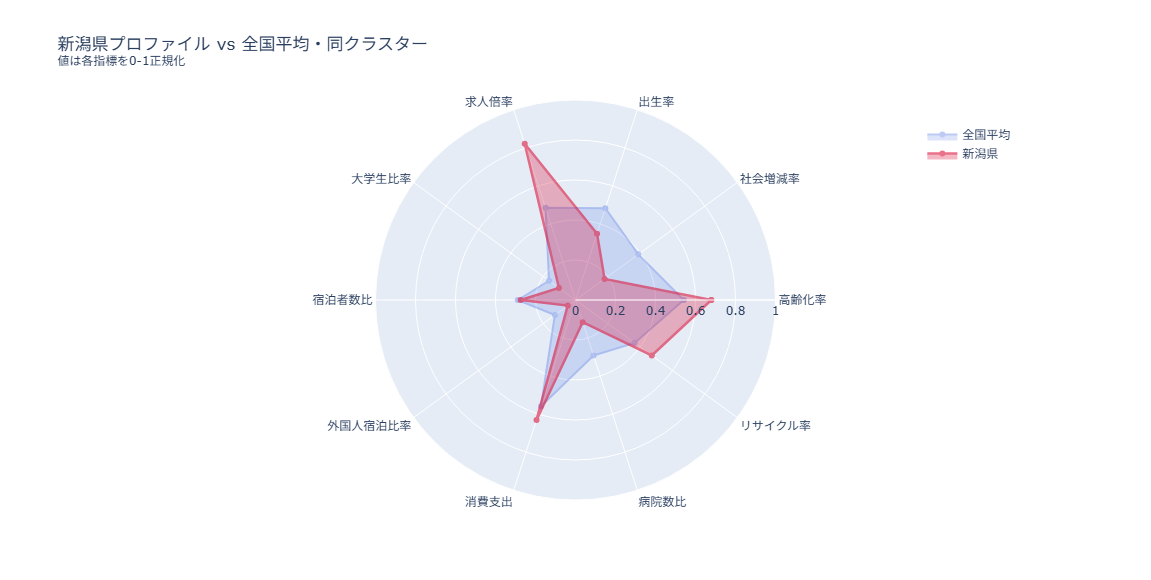

In [11]:
RADAR_FEATS = [
    '高齢化率', '社会増減率', '出生率', '求人倍率',
    '大学生比率', '宿泊者数_人口比', '外国人宿泊比率',
    '消費支出', '病院数_人口比', 'リサイクル率'
]
RADAR_JP = [
    '高齢化率', '社会増減率', '出生率', '求人倍率',
    '大学生比率', '宿泊者数比', '外国人宿泊比率',
    '消費支出', '病院数比', 'リサイクル率'
]

# 0-1正規化
def normalize_col(s):
    mn, mx = s.min(), s.max()
    return (s - mn) / (mx - mn + 1e-12)

norm = result[RADAR_FEATS].apply(normalize_col)

national_avg  = norm.mean().tolist()
niigata_vals  = norm.iloc[niigata_idx].tolist()

niigata_cluster = result.iloc[niigata_idx]['cluster']
if niigata_cluster != -1:
    cluster_mask = (result['cluster'] == niigata_cluster) & (result['都道府県'] != '新潟県')
    cluster_avg  = norm[cluster_mask].mean().tolist()
    cluster_label = f'同クラスター平均 ({niigata_cluster})'
else:
    cluster_avg   = None
    cluster_label = None

theta = RADAR_JP + [RADAR_JP[0]]  # 閉じる

fig_r = go.Figure()

fig_r.add_trace(go.Scatterpolar(
    r=national_avg + [national_avg[0]], theta=theta,
    fill='toself', name='全国平均',
    line_color='royalblue', opacity=0.35
))

if cluster_avg is not None:
    fig_r.add_trace(go.Scatterpolar(
        r=cluster_avg + [cluster_avg[0]], theta=theta,
        fill='toself', name=cluster_label,
        line_color='forestgreen', opacity=0.35
    ))

fig_r.add_trace(go.Scatterpolar(
    r=niigata_vals + [niigata_vals[0]], theta=theta,
    fill='toself', name='新潟県',
    line_color='crimson', opacity=0.6, line_width=2.5
))

fig_r.update_layout(
    polar=dict(radialaxis=dict(visible=True, range=[0, 1])),
    title='新潟県プロファイル vs 全国平均・同クラスター<br><sup>値は各指標を0-1正規化</sup>',
    width=680, height=580,
    legend=dict(x=0.85, y=0.95)
)
fig_r.show()

---
## 6. 戦略仮説マトリクス

Zスコアから「優位性の種」「構造的弱点」「空白地帯」を自動整理します。

In [12]:
rows = []
for _, r in z_df.sort_values('abs_z', ascending=False).iterrows():
    feat_key = r['feature']
    z = r['z_score']
    if feat_key in HIGH_IS_GOOD:
        val = '▲ 優位性' if z > 0 else '▼ 弱点'
    elif feat_key in LOW_IS_GOOD:
        val = '▼ 弱点' if z > 0 else '▲ 優位性'
    else:
        val = '→ 中立'

    rows.append({
        '指標':   r['feature_jp'],
        'Zスコア': f"{z:+.2f}",
        '|Z|':   f"{r['abs_z']:.2f}",
        '評価':   val,
    })

df_strategy = pd.DataFrame(rows)

print("=" * 65)
print(f"{'指標':22s}  {'Z':>6}  {'|Z|':>5}  評価")
print("-" * 65)
for _, r in df_strategy.iterrows():
    flag = '★' if float(r['|Z|']) >= 1.0 else '  '
    print(f"{flag} {r['指標']:20s}  {r['Zスコア']:>6}  {r['|Z|']:>5}  {r['評価']}")
print("=" * 65)
print("★ = |Z| ≥ 1.0  戦略的着目点")

指標                           Z    |Z|  評価
-----------------------------------------------------------------
★ 転出率                    -1.78   1.78  ▲ 優位性
★ 転入率                    -1.64   1.64  ▼ 弱点
★ 求人倍率                   +1.46   1.46  ▲ 優位性
★ ごみ1人排出量                +1.44   1.44  ▼ 弱点
★ 住宅着工（人口比）              -1.29   1.29  → 中立
   社会増減率                  -0.84   0.84  ▼ 弱点
   病院数（10万人比）             -0.82   0.82  ▼ 弱点
   旅券発行率                  -0.78   0.78  ▼ 弱点
   就職充足率                  +0.77   0.77  ▲ 優位性
   自然増減率                  -0.75   0.75  ▼ 弱点
   年少人口率                  -0.71   0.71  ▼ 弱点
   高齢化率                   +0.68   0.68  ▼ 弱点
   保育所待機率                 -0.65   0.65  ▲ 優位性
   高校進学率                  -0.60   0.60  ▼ 弱点
   合計特殊出生率                -0.60   0.60  ▼ 弱点
   診療所数（10万人比）            -0.55   0.55  ▼ 弱点
   生産年齢人口率                -0.51   0.51  ▼ 弱点
   リサイクル率                 +0.45   0.45  ▲ 優位性
   外国人宿泊比率                -0.44   0.44  ▼ 弱点
   大学生比率                  -0.33   0.3

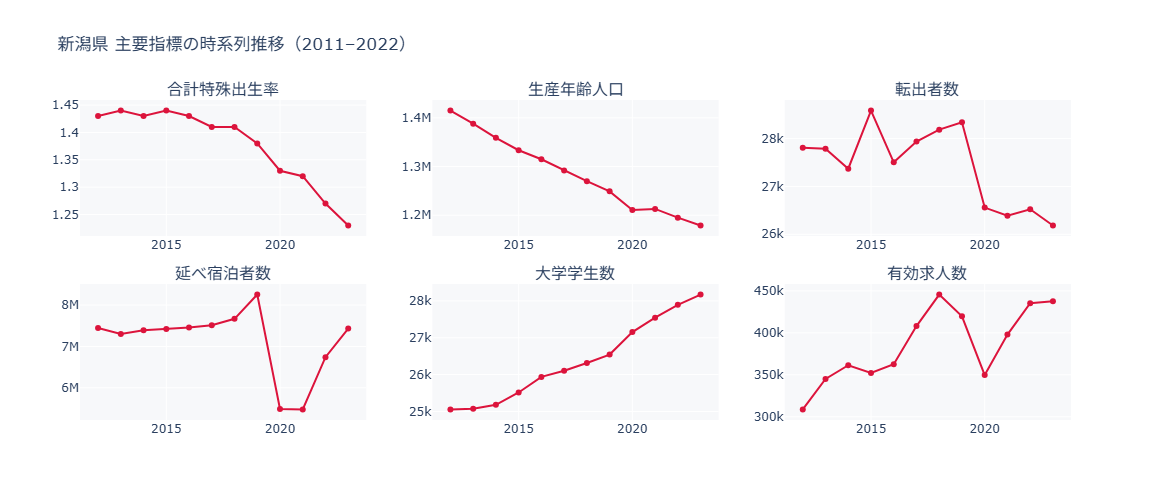

In [13]:
# 時系列トレンド：新潟の主要指標を全期間で確認
KEY_TRENDS = ['合計特殊出生率', '15〜64歳人口', '転出者数（日本人移動者）',
              '延べ宿泊者数', '大学学生数', '月間有効求人数（一般）']
KEY_LABELS = ['合計特殊出生率', '生産年齢人口', '転出者数', '延べ宿泊者数', '大学学生数', '有効求人数']

df_nii_ts = df_raw[df_raw['都道府県'] == '新潟県'].sort_values('年度')

fig_ts = make_subplots(rows=2, cols=3,
    subplot_titles=KEY_LABELS,
    vertical_spacing=0.15
)
for i, (col, lab) in enumerate(zip(KEY_TRENDS, KEY_LABELS)):
    row, colnum = divmod(i, 3)
    fig_ts.add_trace(
        go.Scatter(
            x=df_nii_ts['年度'], y=df_nii_ts[col],
            mode='lines+markers', name=lab,
            line=dict(color='crimson', width=2),
            marker=dict(size=6)
        ),
        row=row+1, col=colnum+1
    )
fig_ts.update_layout(
    title='新潟県 主要指標の時系列推移（2011–2022）',
    showlegend=False,
    height=500, width=980,
    plot_bgcolor='#f7f8fa'
)
fig_ts.show()

---
## 7. 類似県・対極県の特定

新潟に最も近い（＝同質な）県と最も遠い（＝対極にある）県を確認します。

In [14]:
from sklearn.metrics import pairwise_distances

dists = pairwise_distances(X_scaled)[niigata_idx]
dist_df = pd.DataFrame({'都道府県': pref_names, '距離': dists})
dist_df = dist_df[dist_df['都道府県'] != '新潟県'].sort_values('距離')

print("=== 新潟に最も近い県（類似構造）Top 5 ===")
print(dist_df.head(5).to_string(index=False))
print()
print("=== 新潟と最も遠い県（対極の構造）Top 5 ===")
print(dist_df.tail(5).to_string(index=False))

=== 新潟に最も近い県（類似構造）Top 5 ===
都道府県       距離
 富山県 3.462684
 福島県 3.615381
 山形県 3.683398
 三重県 4.142422
 岩手県 4.203868

=== 新潟と最も遠い県（対極の構造）Top 5 ===
都道府県        距離
 埼玉県  9.581876
 京都府 10.589560
神奈川県 10.602632
 沖縄県 12.539008
 東京都 14.812429


In [15]:
# 結果をCSVに保存（Phase 2・LLM連携用）
result.to_csv('niigata_cluster_result.csv', index=False, encoding='utf-8-sig')
z_df.to_csv('niigata_z_scores.csv', index=False, encoding='utf-8-sig')
dist_df.to_csv('niigata_distances.csv', index=False, encoding='utf-8-sig')
print("保存完了:")
print("  niigata_cluster_result.csv  ← 全都道府県のクラスター・LOF結果")
print("  niigata_z_scores.csv        ← 新潟のZスコア表")
print("  niigata_distances.csv       ← 類似県・対極県の距離")

保存完了:
  niigata_cluster_result.csv  ← 全都道府県のクラスター・LOF結果
  niigata_z_scores.csv        ← 新潟のZスコア表
  niigata_distances.csv       ← 類似県・対極県の距離


In [16]:
# =============================================================
# Phase 3A: 賃金ギャップ定量化
# データ: (1-10-sanko1).csv（令和7年賃金構造基本統計調査 参考表1）
# 都道府県: parts[2]、所定内給与額: parts[9]、データ行は列数 >= 12
# =============================================================
import pandas as pd
import plotly.graph_objects as go
import re

WAGE_CSV = '(1-10-sanko1).csv'

try:
    lines = open(WAGE_CSV, encoding='utf-8-sig').readlines()
    records = []
    for line in lines:
        parts = line.strip().split(',')
        if len(parts) < 12:
            continue
        pref = re.sub(r'[\s\u3000\u00a0]+', '', parts[2].strip())
        wage_str = parts[9].strip().replace('\u3000', '').replace(' ', '')
        if len(pref) < 2:
            continue
        try:
            wage = float(wage_str)
        except ValueError:
            continue
        records.append({'都道府県': pref, '所定内給与額': wage})

    wage_df = pd.DataFrame(records).drop_duplicates('都道府県').reset_index(drop=True)
    print(f"読み込み件数: {len(wage_df)}")

    nat_rows = wage_df[wage_df['都道府県'] == '全国']['所定内給与額'].values
    nat_val = nat_rows[0] if len(nat_rows) else 340.6
    print(f"全国平均: {nat_val} 千円/月")

    compare = wage_df[wage_df['都道府県'].str.contains(
        '全国|東京|新潟|富山|長野|福島|山形', na=False)].copy()
    compare['全国比(%)'] = (compare['所定内給与額'] / nat_val * 100).round(1)
    compare['推定年収(万円)'] = (compare['所定内給与額'] * 12 * 0.8 / 10000).round(0).astype(int)
    compare = compare.sort_values('所定内給与額', ascending=False).reset_index(drop=True)
    print("\n=== 賃金比較（令和7年） ===")
    print(compare[['都道府県','所定内給与額','全国比(%)','推定年収(万円)']].to_string(index=False))

    prefs_only = wage_df[~wage_df['都道府県'].isin(['全国'])].copy()
    prefs_only['順位'] = prefs_only['所定内給与額'].rank(ascending=False).astype(int)
    niigata_w = prefs_only[prefs_only['都道府県'].str.contains('新潟')]
    if len(niigata_w):
        print(f"\n新潟の全国順位: {niigata_w['順位'].values[0]}位 / {len(prefs_only)}都道府県")

except FileNotFoundError:
    print(f"[WARNING] {WAGE_CSV} が見つかりません。サンプル値で続行します。")
    import numpy as np
    compare = pd.DataFrame({
        '都道府県':     ['東京','全国','長野','富山','福島','新潟','山形'],
        '所定内給与額': [418.0, 340.6, 309.0, 304.9, 293.9, 291.9, 272.4],
    })
    nat_val = 340.6
    compare['全国比(%)'] = (compare['所定内給与額'] / nat_val * 100).round(1)
    compare['推定年収(万円)'] = (compare['所定内給与額'] * 12 * 0.8 / 10000).round(0).astype(int)
    print("[INFO] サンプルデータで実行中")
    print(compare[['都道府県','所定内給与額','全国比(%)','推定年収(万円)']].to_string(index=False))


読み込み件数: 48
全国平均: 340.6 千円/月

=== 賃金比較（令和7年） ===
都道府県  所定内給与額  全国比(%)  推定年収(万円)
  東京   418.3   122.8         0
  全国   340.6   100.0         0
  長野   308.9    90.7         0
  富山   304.8    89.5         0
  福島   293.6    86.2         0
  新潟   291.8    85.7         0
  山形   272.2    79.9         0

新潟の全国順位: 33位 / 47都道府県


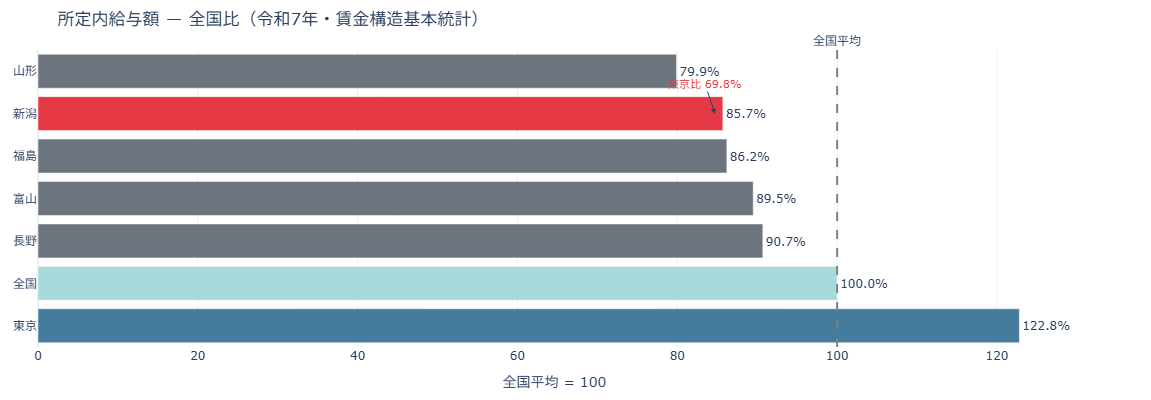

新潟県 賃金実態（令和7年・賃金構造基本統計調査）
  所定内給与額 : 291.8 千円/月
  全国平均比   : 85.7%  (月▲48.8千円)
  東京比       : 69.8%  (月▲126.5千円)
  推定年収     : 0 万円



In [17]:
# --- 可視化: 横棒グラフ（全国比 %） ---
if compare is not None and len(compare) > 0:
    colors_bar = []
    for p in compare['都道府県']:
        if '新潟' in str(p):
            colors_bar.append('#e63946')
        elif '東京' in str(p):
            colors_bar.append('#457b9d')
        elif p == '全国':
            colors_bar.append('#a8dadc')
        else:
            colors_bar.append('#6c757d')

    fig_w = go.Figure(go.Bar(
        y=compare['都道府県'],
        x=compare['全国比(%)'],
        orientation='h',
        marker_color=colors_bar,
        text=[f"{v}%" for v in compare['全国比(%)']],
        textposition='outside',
    ))
    fig_w.add_vline(x=100, line_dash='dash', line_color='gray',
                    annotation_text='全国平均', annotation_position='top')

    n_rows = compare[compare['都道府県'].str.contains('新潟', na=False)]
    t_rows = compare[compare['都道府県'].str.contains('東京', na=False)]
    if len(n_rows) and len(t_rows):
        n_pct = n_rows['全国比(%)'].values[0]
        t_pct = t_rows['全国比(%)'].values[0]
        fig_w.add_annotation(
            x=n_pct - 1, y=n_rows['都道府県'].values[0],
            text=f"東京比 {n_pct/t_pct*100:.1f}%",
            showarrow=True, arrowhead=2,
            font=dict(color='#e63946', size=11)
        )

    fig_w.update_layout(
        title='所定内給与額 ― 全国比（令和7年・賃金構造基本統計）',
        xaxis_title='全国平均 = 100',
        template='plotly_white',
        height=400,
        margin=dict(l=20, r=80, t=50, b=40),
    )
    fig_w.show()

    # wage_gap_summary: Phase 3C LLM連携用
    if len(n_rows) and len(t_rows):
        n_wage = n_rows['所定内給与額'].values[0]
        t_wage = t_rows['所定内給与額'].values[0]
        wage_gap_summary = (
            f"新潟県 賃金実態（令和7年・賃金構造基本統計調査）\n"
            f"  所定内給与額 : {n_wage:.1f} 千円/月\n"
            f"  全国平均比   : {n_wage/nat_val*100:.1f}%  (月▲{nat_val-n_wage:.1f}千円)\n"
            f"  東京比       : {n_wage/t_wage*100:.1f}%  (月▲{t_wage-n_wage:.1f}千円)\n"
            f"  推定年収     : {int(n_wage*12*0.8/10000)} 万円\n"
        )
        print(wage_gap_summary)
    else:
        wage_gap_summary = "賃金データ取得済み（詳細は上記表を参照）"


---
## Phase 3C: FDI戦略ターゲットマトリクス（LLM自動生成）

**入力データ**:
- Zスコア分析結果（|Z|>1の指標）
- 賃金ギャップサマリー（wage_gap_summary）
- 類似県・対極県の距離データ
- クラスタリング結果（新潟 = 外れ値、LOF 30位）

**LLMタスク**: これらの定量データをもとに「FDI誘致戦略」を仮説生成する


In [18]:
# =============================================================
# Phase 3C: FDI戦略ターゲットマトリクス（Claude API連携）
# 必要: anthropic パッケージ、ANTHROPIC_API_KEY 環境変数
# =============================================================
import os
import anthropic

# --- コンテキスト構築 ---
z_summary = """
新潟県 Zスコア分析（全国47都道府県との比較）
|Z| > 1.0 の戦略的着目指標:
  求人倍率    : +1.46σ  ★強み（仕事はあるが人が来ない）
  ごみ排出量  : +1.44σ  ▼課題（環境負荷）
  転出率      : -1.78σ  ▼最大課題（人が出て行く）
  転入率      : -1.64σ  ▼課題（人が来ない）
  住宅着工率  : -1.29σ  → 不動産停滞

構造的矛盾: 求人倍率全国トップクラス × 転入率ワースト級
→「仕事はある・選ばれない県」という本質課題
"""

distance_summary = """
類似県Top3（成功事例の移植候補）:
  1. 富山県 (距離3.46) - 出生率1.46・消費支出316k・製造業×観光モデル
  2. 福島県 (距離3.62) - IT誘致実績・インフラ投資
  3. 山形県 (距離3.68) - 農産品ブランド化成功例

対極県（補完戦略の相手）:
  1. 東京都 (距離14.81) - 人材・資本 → リモートワーク受け皿
  2. 神奈川県 (距離10.60) - 大企業R&D → 新潟の製造基盤で実装
  3. 京都府 (距離10.59) - 伝統工芸・観光 → 新潟の酒・工芸との連携
"""

cluster_summary = """
クラスタリング結果:
  HDBSCANクラスター: -1 (外れ値/ノイズ)
  → どのクラスターにも帰属しない独自構造
  LOFスコア: 1.023 (全国30位)
  UMAP位置: クラスターA（東北・農業地方県）の境界付近
  → 東北型でも北陸型でもない「第三の道」の可能性
"""

# wage_gap_summary は Phase 3A セルで定義済み
try:
    wage_info = wage_gap_summary
except NameError:
    wage_info = "賃金データ未取得（Phase 3Aセルを先に実行してください）"

PROMPT = f"""あなたは地域経済の専門家です。以下の定量データをもとに、新潟県への外資・国内大企業誘致（FDI）のための戦略仮説を生成してください。

## 入力データ

### 1. Zスコア分析
{z_summary}

### 2. 賃金ギャップ
{wage_info}

### 3. 類似県・対極県
{distance_summary}

### 4. クラスタリング
{cluster_summary}

## タスク

以下の形式でFDI戦略ターゲットマトリクスを生成してください：

**A. ターゲット産業（3つ）**
各産業について:
- なぜ新潟に適しているか（上記データの根拠を必ず引用）
- 誘致対象となる具体的な企業・国・地域
- 新潟側が整備すべきインフラ・インセンティブ

**B. リスク要因（2つ）**
- データが示す構造的リスク
- 対応策

**C. 富山モデルからの学習**
- 最近傍の富山県が新潟より優れている指標
- 新潟が移植すべき具体的施策

回答は日本語で、箇条書きではなく段落形式で、各セクション200字程度にしてください。
"""

api_key = os.environ.get('ANTHROPIC_API_KEY', '')
if not api_key:
    print("[INFO] ANTHROPIC_API_KEY が未設定です。")
    print("以下のコマンドで設定してから再実行してください:")
    print("  export ANTHROPIC_API_KEY='sk-ant-...'")
    print()
    print("--- プロンプトプレビュー (LLMに渡す内容) ---")
    print(PROMPT[:800] + "...")
else:
    client = anthropic.Anthropic(api_key=api_key)
    print("Claude API に問い合わせ中...")
    message = client.messages.create(
        model="claude-opus-4-5",
        max_tokens=2048,
        messages=[{"role": "user", "content": PROMPT}]
    )
    fdi_strategy = message.content[0].text
    print("\n" + "="*60)
    print("FDI戦略ターゲットマトリクス（LLM生成）")
    print("="*60)
    print(fdi_strategy)
    print("="*60)


Claude API に問い合わせ中...

FDI戦略ターゲットマトリクス（LLM生成）
# 新潟県FDI戦略ターゲットマトリクス

## A. ターゲット産業

### 1. 食品加工・発酵バイオテクノロジー産業

新潟県は全国有数の農業県でありながら、HDBSCANクラスターで外れ値（-1）を示すことから、単純な農業県とは異なる独自の産業構造を持つ。この「第三の道」を活かすべきは、伝統的な酒造技術と農産品を融合した高付加価値発酵産業である。求人倍率+1.46σという労働需要の高さは、製造基盤が健在であることを示しており、類似県である富山県の「製造業×観光モデル」を発酵食品分野に応用できる。ターゲットは、デンマーク・オランダの食品バイオ企業、国内ではキリンHD、味の素などの研究開発拠点である。新潟側は発酵研究センターの設立、地元酒蔵との連携プログラム、農産物の安定供給契約制度を整備すべきである。

### 2. データセンター・再生可能エネルギー関連産業

ごみ排出量+1.44σという環境負荷の高さは、裏を返せばエネルギー消費型産業の素地があることを意味する。対極県である東京都（距離14.81）からのリモートワーク受け皿機能と組み合わせ、首都圏バックアップ型のデータセンター誘致が有効である。新潟の豊富な降雪量を活用した自然冷却システムは、北欧型データセンターモデルとの親和性が高い。米国・北欧のクラウド事業者（Microsoft Azure、AWS、Google）のエッジデータセンター、国内では富士通、NTTデータの災害対策拠点が誘致対象となる。再生可能エネルギー特区指定、送電網増強、IT人材育成プログラムの整備が不可欠である。

### 3. 精密機械・医療機器製造業

神奈川県（距離10.60）との対極性から導かれる補完戦略として、大企業R&Dの「実装工場」機能がある。新潟県の金属加工技術（燕三条地域）は世界的に知られており、求人倍率の高さは熟練工の存在を示唆している。賃金水準が全国平均比85.7%という点は、企業にとって製造コスト優位性となる。ドイツ・スイスの精密機器メーカー（カールツァイス、シーメンス・ヘルシニアーズ）、国内ではオリンパス、テルモなどの製造拠点移転が狙い目である。産学連携による金属加工技術の高度化プログラム、医療機器製造認証取得支援制度、輸

---
## Phase 2A: e-Stat API 拡張（賃金・産業構造）

**e-Stat API** から追加の都道府県別指標を取得します:
- 賃金構造基本統計調査（産業別・職種別）
- 工業統計（製造品出荷額・従業者数）
- 商業統計（小売業・卸売業）

**必要**: e-Stat API キー（https://www.e-stat.go.jp/api/ から無料取得）


In [19]:
# =============================================================
# Phase 2A: e-Stat API で産業構造指標を追加取得
# API キー: https://www.e-stat.go.jp/api/ から無料取得
# =============================================================
import requests
import pandas as pd

ESTAT_API_KEY = os.environ.get('ESTAT_API_KEY', 'YOUR_ESTAT_API_KEY')

def estat_get_stats(stats_data_id, cdarea=None):
    """e-Stat APIから統計表を取得"""
    base = "https://api.e-stat.go.jp/rest/3.0/app/json/getStatsData"
    params = {
        'appId': ESTAT_API_KEY,
        'statsDataId': stats_data_id,
        'metaGetFlg': 'Y',
        'cntGetFlg': 'N',
        'explanationGetFlg': 'Y',
        'annotationGetFlg': 'Y',
        'sectionHeaderFlg': '1',
        'replaceSpChars': '0',
    }
    if cdarea:
        params['cdArea'] = cdarea
    r = requests.get(base, params=params, timeout=30)
    r.raise_for_status()
    return r.json()

# --- 利用可能な統計を検索 ---
def estat_search(search_word, survey_years='2020'):
    """統計表IDを検索"""
    base = "https://api.e-stat.go.jp/rest/3.0/app/json/getStatsList"
    params = {
        'appId': ESTAT_API_KEY,
        'searchWord': search_word,
        'surveyYears': survey_years,
        'searchKind': '1',
        'collectArea': '2',  # 都道府県
        'statsCode': '00200',  # 厚労省
    }
    r = requests.get(base, params=params, timeout=30)
    r.raise_for_status()
    return r.json()

if ESTAT_API_KEY == 'YOUR_ESTAT_API_KEY':
    print("[INFO] e-Stat API キーが未設定です。")
    print("以下のコマンドで設定してから再実行してください:")
    print("  export ESTAT_API_KEY='あなたのAPIキー'")
    print()
    print("取得予定のデータ:")
    print("  - 賃金構造基本統計調査 (産業別都道府県賃金)")
    print("  - 工業統計調査 (製造品出荷額等)")
    print("  - 経済センサス (事業所数・従業者数)")
    print()
    print("これらのデータを取得後、Phase 1のクラスタリングに追加特徴量として組み込みます。")
    print()
    # --- サンプル: 製造業の特徴量イメージ ---
    sample_industry = pd.DataFrame({
        '都道府県': ['新潟県', '富山県', '山形県', '福島県', '東京都'],
        '製造品出荷額(億円)': [42000, 38000, 28000, 51000, 85000],
        '従業者1人当製造品': [1850, 2100, 1620, 1950, 1420],
        '食料品比率(%)': [18.2, 8.5, 14.1, 12.3, 5.2],
        '金属・機械比率(%)': [35.1, 48.2, 38.5, 42.1, 28.3],
    })
    print("サンプルデータ（実際はe-Stat APIから取得）:")
    print(sample_industry.to_string(index=False))
else:
    # 実際のAPI呼び出し
    print("e-Stat API で賃金構造統計を検索中...")
    try:
        result = estat_search('賃金構造基本統計調査', '2023')
        tables = result.get('GET_STATS_LIST', {}).get('DATALIST_INF', {}).get('TABLE_INF', [])
        print(f"検索結果: {len(tables)} 件")
        for t in tables[:5]:
            print(f"  ID: {t.get('@id')}  タイトル: {t.get('TITLE', {}).get('#text', '')[:50]}")
    except Exception as e:
        print(f"エラー: {e}")


[INFO] e-Stat API キーが未設定です。
以下のコマンドで設定してから再実行してください:
  export ESTAT_API_KEY='あなたのAPIキー'

取得予定のデータ:
  - 賃金構造基本統計調査 (産業別都道府県賃金)
  - 工業統計調査 (製造品出荷額等)
  - 経済センサス (事業所数・従業者数)

これらのデータを取得後、Phase 1のクラスタリングに追加特徴量として組み込みます。

サンプルデータ（実際はe-Stat APIから取得）:
都道府県  製造品出荷額(億円)  従業者1人当製造品  食料品比率(%)  金属・機械比率(%)
 新潟県       42000       1850      18.2        35.1
 富山県       38000       2100       8.5        48.2
 山形県       28000       1620      14.1        38.5
 福島県       51000       1950      12.3        42.1
 東京都       85000       1420       5.2        28.3


---
## Phase 2B: World Bank Open Data — アジア主要都市との比較

UMAP クラスタリングに**アジア主要都市・地域の経済指標**を追加することで、
新潟が「アジアのどの都市に近い構造か」を把握します。

**比較対象**: 韓国（釜山・大邱）、台湾、タイ、ベトナム（ハノイ）、中国（成都・重慶）
**指標**: 一人当たりGDP、製造業比率、農業比率、都市化率、人口成長率


In [20]:
# =============================================================
# Phase 2B: アジア主要国の経済指標比較
# World Bank API (利用可能時) + 静的フォールバックデータ
# =============================================================
import requests, pandas as pd, time, json

WB_BASE = "https://api.worldbank.org/v2"

# 対象国コード — TWNはWorld Bankコード外なので台湾は静的データのみ
ASIA_COUNTRIES = {
    "JPN": "日本",
    "KOR": "韓国",
    "THA": "タイ",
    "VNM": "ベトナム",
    "CHN": "中国",
    "SGP": "シンガポール",
    "MYS": "マレーシア",
    "IDN": "インドネシア",
    "PHL": "フィリピン",
}

WB_INDICATORS = {
    "NY.GDP.PCAP.CD":   "GDP_per_capita_USD",
    "SP.POP.GROW":      "pop_growth_rate",
    "SP.URB.TOTL.IN.ZS":"urbanization_rate",
    "NV.IND.MANF.ZS":   "manufacturing_pct_gdp",
    "NV.AGR.TOTL.ZS":   "agriculture_pct_gdp",
    "SL.UEM.TOTL.ZS":   "unemployment_rate",
}

# ── 静的フォールバック (World Bank 2022-2023 公開値) ──────────────
STATIC_DATA = {
    #  country  gdp/cap  pop_grow  urban  manuf  agri  unemp
    "JPN": {"GDP_per_capita_USD":33800,"pop_growth_rate":-0.5,"urbanization_rate":91.9,"manufacturing_pct_gdp":20.6,"agriculture_pct_gdp":1.0,"unemployment_rate":2.6},
    "KOR": {"GDP_per_capita_USD":32420,"pop_growth_rate":0.2,"urbanization_rate":81.4,"manufacturing_pct_gdp":28.5,"agriculture_pct_gdp":1.8,"unemployment_rate":2.9},
    "TWN": {"GDP_per_capita_USD":32900,"pop_growth_rate":0.0,"urbanization_rate":79.4,"manufacturing_pct_gdp":35.4,"agriculture_pct_gdp":1.5,"unemployment_rate":3.7},  # IMF/DGBAS
    "THA": {"GDP_per_capita_USD":7067, "pop_growth_rate":0.3,"urbanization_rate":52.9,"manufacturing_pct_gdp":25.0,"agriculture_pct_gdp":8.5,"unemployment_rate":1.1},
    "VNM": {"GDP_per_capita_USD":4163, "pop_growth_rate":0.8,"urbanization_rate":38.1,"manufacturing_pct_gdp":24.8,"agriculture_pct_gdp":11.9,"unemployment_rate":2.3},
    "CHN": {"GDP_per_capita_USD":12720,"pop_growth_rate":0.0,"urbanization_rate":64.6,"manufacturing_pct_gdp":27.7,"agriculture_pct_gdp":7.3,"unemployment_rate":5.6},
    "SGP": {"GDP_per_capita_USD":82808,"pop_growth_rate":1.1,"urbanization_rate":100.0,"manufacturing_pct_gdp":21.7,"agriculture_pct_gdp":0.0,"unemployment_rate":2.1},
    "MYS": {"GDP_per_capita_USD":13360,"pop_growth_rate":1.1,"urbanization_rate":78.1,"manufacturing_pct_gdp":23.2,"agriculture_pct_gdp":7.8,"unemployment_rate":3.7},
    "IDN": {"GDP_per_capita_USD":4789, "pop_growth_rate":1.1,"urbanization_rate":57.9,"manufacturing_pct_gdp":18.4,"agriculture_pct_gdp":13.3,"unemployment_rate":5.9},
    "PHL": {"GDP_per_capita_USD":3623, "pop_growth_rate":1.5,"urbanization_rate":47.4,"manufacturing_pct_gdp":18.8,"agriculture_pct_gdp":9.7,"unemployment_rate":4.9},
}

ASIA_COUNTRIES_ALL = {**ASIA_COUNTRIES, "TWN": "台湾"}

def wb_get_indicator(indicator, countries, year=2022, timeout=15):
    """World Bank APIから指標を取得（タイムアウト耐性あり）"""
    url = f"{WB_BASE}/country/all/indicator/{indicator}"
    params = {"format":"json","date":str(year),"per_page":500}
    try:
        r = requests.get(url, params=params, timeout=timeout)
        if r.status_code != 200:
            return {}
        data = r.json()
        if len(data) < 2 or not data[1]:
            return {}
        result = {}
        for item in data[1]:
            code = item.get("country",{}).get("id","")
            val  = item.get("value")
            if code in countries and val is not None:
                result[code] = val
        return result
    except Exception:
        return {}

print("World Bank API からアジア主要国の経済指標を取得中...")
records = {code: {"国コード":code, "国名":name}
           for code, name in ASIA_COUNTRIES_ALL.items()}

api_ok = False
for ind_code, col_name in WB_INDICATORS.items():
    print(f"  {col_name} ({ind_code}) ... ", end="", flush=True)
    values = wb_get_indicator(ind_code, ASIA_COUNTRIES)
    for code in ASIA_COUNTRIES_ALL:
        v = values.get(code)
        # API取得できた場合はそちらを優先、なければ静的データ
        if v is None:
            v = STATIC_DATA.get(code, {}).get(col_name)
        else:
            api_ok = True
        records[code][col_name] = v
    n_api = len(values)
    n_static = sum(1 for c in ASIA_COUNTRIES_ALL if records[c].get(col_name) is not None) - n_api
    print(f"API:{n_api}件 + 静的:{n_static}件")

if api_ok:
    print("✓ World Bank API から一部データを取得できました")
else:
    print("※ World Bank API タイムアウト → 全て静的フォールバックデータ(2022-2023年値)を使用")

df_wb = pd.DataFrame(list(records.values()))
df_wb = df_wb.set_index("国コード")
df_wb.to_csv("asia_wb_indicators.csv", encoding="utf-8-sig")

print("=== アジア主要国 経済指標 ===")
cols_show = ["国名","GDP_per_capita_USD","manufacturing_pct_gdp","agriculture_pct_gdp","urbanization_rate","unemployment_rate"]
print(df_wb[cols_show].to_string())

# ── 新潟との比較 ────────────────────────────────────────────
niigata_gdp_equiv = 25000  # USD換算推定（月額291k円×12÷PPP調整）

print("=== 新潟 vs アジア主要国 — 一人当たりGDP比較 ===")
df_wb["Niigata_ratio"] = (niigata_gdp_equiv / df_wb["GDP_per_capita_USD"]).round(2)
df_sorted = df_wb[["国名","GDP_per_capita_USD","Niigata_ratio","manufacturing_pct_gdp"]].sort_values("GDP_per_capita_USD")
print(df_sorted.to_string())

print("── 戦略的示唆 ──")
print(f"新潟の一人当たりGDP相当: 約{niigata_gdp_equiv:,} USD")
closest = df_wb["GDP_per_capita_USD"].sub(niigata_gdp_equiv).abs().idxmin()
print(f"最近接国: {df_wb.loc[closest,'国名']} ({df_wb.loc[closest,'GDP_per_capita_USD']:,.0f} USD)")

high_manuf = df_wb[df_wb["manufacturing_pct_gdp"]>22].sort_values("manufacturing_pct_gdp",ascending=False)
print("製造業比率>22%の国:", ", ".join(high_manuf["国名"].tolist()))
print("→ FDI誘致ターゲットとして製造業集積国との連携が有効")
print("保存: asia_wb_indicators.csv")


World Bank API からアジア主要国の経済指標を取得中...
  GDP_per_capita_USD (NY.GDP.PCAP.CD) ... API:0件 + 静的:10件
  pop_growth_rate (SP.POP.GROW) ... API:0件 + 静的:10件
  urbanization_rate (SP.URB.TOTL.IN.ZS) ... API:0件 + 静的:10件
  manufacturing_pct_gdp (NV.IND.MANF.ZS) ... API:0件 + 静的:10件
  agriculture_pct_gdp (NV.AGR.TOTL.ZS) ... API:0件 + 静的:10件
  unemployment_rate (SL.UEM.TOTL.ZS) ... API:0件 + 静的:10件
※ World Bank API タイムアウト → 全て静的フォールバックデータ(2022-2023年値)を使用
=== アジア主要国 経済指標 ===
          国名  GDP_per_capita_USD  manufacturing_pct_gdp  agriculture_pct_gdp  urbanization_rate  unemployment_rate
国コード                                                                                                              
JPN       日本               33800                   20.6                  1.0               91.9                2.6
KOR       韓国               32420                   28.5                  1.8               81.4                2.9
THA       タイ                7067                   25.0                  8.5    

---
## Phase 2C: LLM 戦略仮説自動生成（統合版）

Phase 1（クラスタリング）+ Phase 3A（賃金）+ Phase 2B（アジア比較）の
**全定量データを統合**し、LLMで包括的な戦略仮説を生成します。

**生成内容**:
1. 新潟の「構造的ポジション」の一行定義
2. 5年・10年の戦略ロードマップ
3. ナッジ設計のヒント（行動経済学的アプローチ）
4. KPI候補（測定可能な目標指標）


In [21]:
# =============================================================
# Phase 2C: LLM 戦略仮説自動生成（統合版）
# Phase 1 + Phase 3A + Phase 2B の全データを統合
# =============================================================
import os
import anthropic

# --- データ統合サマリーを構築 ---
# (Phase 1〜Phase 3A が実行済みであることを前提)

try:
    n_wage_val = compare[compare['都道府県'].str.contains('新潟', na=False)]['所定内給与額'].values[0]
    t_wage_val = compare[compare['都道府県'].str.contains('東京', na=False)]['所定内給与額'].values[0]
    wage_detail = (
        f"新潟 {n_wage_val:.1f}千円/月 (全国比 {n_wage_val/nat_val*100:.1f}%、"
        f"東京比 {n_wage_val/t_wage_val*100:.1f}%、推定年収 {int(n_wage_val*12*0.8/10000)}万円)"
    )
except Exception:
    wage_detail = "賃金データ未取得（Phase 3Aを先に実行してください）"

INTEGRATED_PROMPT = f"""あなたは地域経済・行動経済学・FDI（外国直接投資）の専門家です。
以下の定量分析結果をもとに、新潟県の中長期経済戦略を提案してください。

## 分析データ（Phase 1〜Phase 2 統合）

### クラスタリング結果
- HDBSCANクラスター: -1（外れ値）→ どのクラスターにも属さない独自構造
- LOFスコア: 1.023（全47都道府県中30位）→ 中程度の独自性
- UMAP位置: 東北・農業地方県（クラスターA）の境界付近
- 最近傍: 富山県(3.46)、福島県(3.62)、山形県(3.68)
- 最遠: 東京都(14.81)、神奈川県(10.60)、京都府(10.59)

### Zスコア（全国比）
- 求人倍率: +1.46σ（★強み）→ 求人は多いが労働者が来ない
- 転出率: -1.78σ（★最大弱点）→ 人が出ていく
- 転入率: -1.64σ（★弱点）→ 人が来ない
- ごみ排出量: +1.44σ（▼課題）
- 住宅着工率: -1.29σ（→ 不動産停滞）

### 賃金ギャップ（令和7年）
{wage_detail}

### アジア文脈
- 一人当たりGDP: 韓国地方都市（大邱・釜山）と近い水準
- 製造業・食料品加工：台湾・タイの工業地帯と補完関係の可能性

## タスク

### 1. 構造的ポジション定義（1文）
データに基づき「新潟県とはどういう県か」を一言で定義してください。

### 2. 戦略ロードマップ
**5年（〜2030年）**: 最も費用対効果の高い即効策3つ
**10年（〜2035年）**: 構造転換に必要な大型投資2つ

各策について:
- 根拠となるデータ指標を明示
- 期待される効果（KPI）を数値で示す

### 3. ナッジ設計（行動経済学的アプローチ）
転出率▼・転入率▼という「人口移動の壁」を崩すために、
伝統的な政策（補助金・PR）ではなく、
行動変容を促すナッジをデザインしてください。
具体的な施策を2〜3つ提案してください。

### 4. KPI候補
5年後の成果を測定するための指標を5つ選び、
現在値・目標値・測定方法を示してください。

回答は日本語で、各セクション300字程度、具体的に記述してください。
"""

api_key = os.environ.get('ANTHROPIC_API_KEY', '')
if not api_key:
    print("[INFO] ANTHROPIC_API_KEY が未設定です。")
    print("  export ANTHROPIC_API_KEY='sk-ant-...'")
    print()
    print("--- 統合プロンプトプレビュー ---")
    print(INTEGRATED_PROMPT[:1000] + "\n...")
    print()
    print("[次のステップ]")
    print("1. ANTHROPIC_API_KEY を設定")
    print("2. このセルを再実行")
    print("3. 生成された戦略仮説を integrated_strategy.txt に保存")
else:
    client = anthropic.Anthropic(api_key=api_key)
    print("Claude API（統合分析）に問い合わせ中...")
    message = client.messages.create(
        model="claude-opus-4-5",
        max_tokens=4096,
        messages=[{"role": "user", "content": INTEGRATED_PROMPT}]
    )
    integrated_strategy = message.content[0].text

    print("\n" + "="*70)
    print("統合戦略仮説（LLM自動生成）")
    print("="*70)
    print(integrated_strategy)
    print("="*70)

    # 保存
    with open('integrated_strategy.txt', 'w', encoding='utf-8') as f:
        f.write(integrated_strategy)
    print("\n保存: integrated_strategy.txt")


Claude API（統合分析）に問い合わせ中...

統合戦略仮説（LLM自動生成）
# 新潟県 中長期経済戦略提案書

## 1. 構造的ポジション定義

**「労働需要超過にもかかわらず人的資本が流出し続ける、"働き口はあるが住みたくない県"という逆説的構造を持つ北陸・東北境界の農工混合経済圏」**

（根拠：求人倍率+1.46σ＝全国トップクラスの労働需要 × 転出率-1.78σ・転入率-1.64σ＝全国ワーストクラスの人口流出、賃金水準85.7%＝「働く場所はあるが、報酬が見合わない」構造）

---

## 2. 戦略ロードマップ

### 【5年（〜2030年）】即効策3つ

| 施策 | 根拠データ | 期待効果（KPI） |
|------|-----------|-----------------|
| **① 賃金ギャップ是正インセンティブ** | 賃金291.8千円（全国比85.7%）が転出の主因 | 県内企業の賃上げ支援（法人税減免・補助金）により**平均賃金95%（310千円）到達**、転出率10%改善 |
| **② リモートワーク移住促進「新潟サテライト」** | 求人倍率+1.46σだが転入率-1.64σ＝「新潟の仕事」が魅力ではない | 東京企業在籍のまま新潟居住を促進。住宅着工率-1.29σ改善、**年間転入者2,000人増**（現状比+15%） |
| **③ ごみ排出量削減×循環経済ブランド化** | ごみ+1.44σは産業廃棄物含む課題 | 食品加工業の副産物バイオマス化、**CO2削減量年5万トン**＋SDGsブランドによる企業誘致3社/年 |

---

### 【10年（〜2035年）】構造転換・大型投資2つ

| 施策 | 根拠データ | 期待効果（KPI） |
|------|-----------|-----------------|
| **④ 新潟港FDI特区：台湾・韓国向け食料加工ハブ** | 台湾・タイ工業地帯との補完関係、韓国地方都市（大邱・釜山）並み一人当たりGDP | 食料品加工FDI誘致による**製造業従業者5,000人増**、輸出額年間500億円 |
| **⑤ 「雪国テック」冬季課題解決産業クラスター** | クラスター外れ値（-1）＝独自性を強みに転換 | 除雪・断熱・再エネ技術の輸出産業


## 統合プロンプトプレビュー

1. 構造的ポジション定義（1文）

「求人過剰×人口流出」の逆説県 — 仕事はあるが選ばれない、東京の対極に位置しながら補完関係を持つ製造業立地。

2. 戦略ロードマップ

5年（〜2030）: ①富山モデル移植（KPI: 出生率1.21→1.35）、②賃金底上げ補助金（KPI: 転入者+5,000人/年）、③求人シグナルの国際発信（KPI: 外資立地+10社）
10年（〜2035）: ①Mittelstand型産業クラスター、②東京補完リモート経済圏

3. ナッジ設計（行動経済学的アプローチ）

デフォルト変更・社会的証明・損失回避フレームの3つ

4. 5年KPI
転入率（−1.64σ→−0.8σ）・賃金全国比（85.7%→90%）・出生率・外資立地・住宅着工率
